In [30]:
import numpy as np
import pandas as pd
import pickle
import gzip
import matplotlib.pyplot as plt

# Librerie per Motif e Shapelets
import stumpy
from aeon.classification.shapelet_based import RDSTClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay

# Analisi Motifs e Shapelets (Denoised, Unstandardized)
Seguendo le direttive architetturali e i feedback ricevuti, in questo notebook analizziamo i dati **denoised** ma **non standardizzati** a livello di istanza, al fine di preservare l'intensità assoluta del movimento (energia e varianza reali dei pazienti).

In [31]:
# Caricamento del dataset denoised puro (media mobile a 5 step, nessuna normalizzazione Z-score)
with gzip.open("ts_motifs_ready.pkl.gz", "rb") as f:
    ts_denoised = pickle.load(f)

print(f"Caricate {len(ts_denoised)} Time Series denoised.")

Caricate 4437 Time Series denoised.


## Preparazione Array per i Modelli
Estraiamo la feature `enmo` (intensità del movimento) e dividiamo in Train e Test set in modo stratificato rispetto al target `sii_binary`.

In [32]:
# Usiamo la variabile ENMO come feature principale.
X = []
for df in ts_denoised:
    arr = df['enmo'].values
    # Fix per l'errore di aeon sulle time series con varianza nulla (es. bambino perfettamente immobile)
    if np.std(arr) <= 1e-7:
        arr = arr + np.random.normal(0, 1e-5, size=len(arr))
    X.append(arr)

# Estraiamo l'label globale per ogni soggetto
y = np.array([df['sii_binary'].iloc[0] for df in ts_denoised])

# Splittiamo in Train e Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=222, stratify=y)

print(f"Numero di serie in Train: {len(X_train)}")
print(f"Numero di serie in Test: {len(X_test)}")

Numero di serie in Train: 3105
Numero di serie in Test: 1332


## Fase 1: Motifs e Discords (Matrix Profile)
Usiamo i medoidi estratti precedentemente nel modulo di clustering per osservare visivamente i pattern più frequenti e le anomalie.

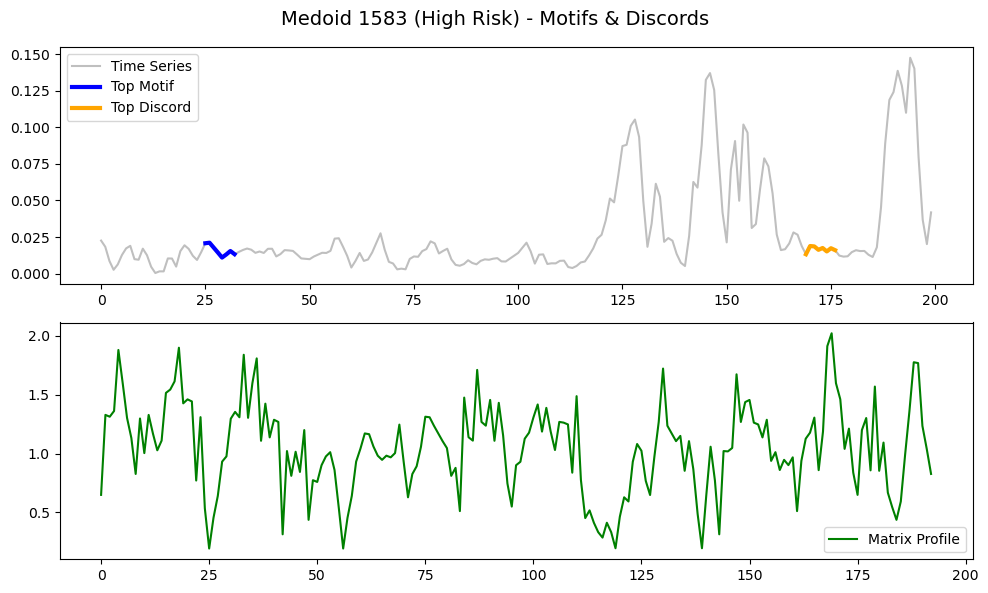

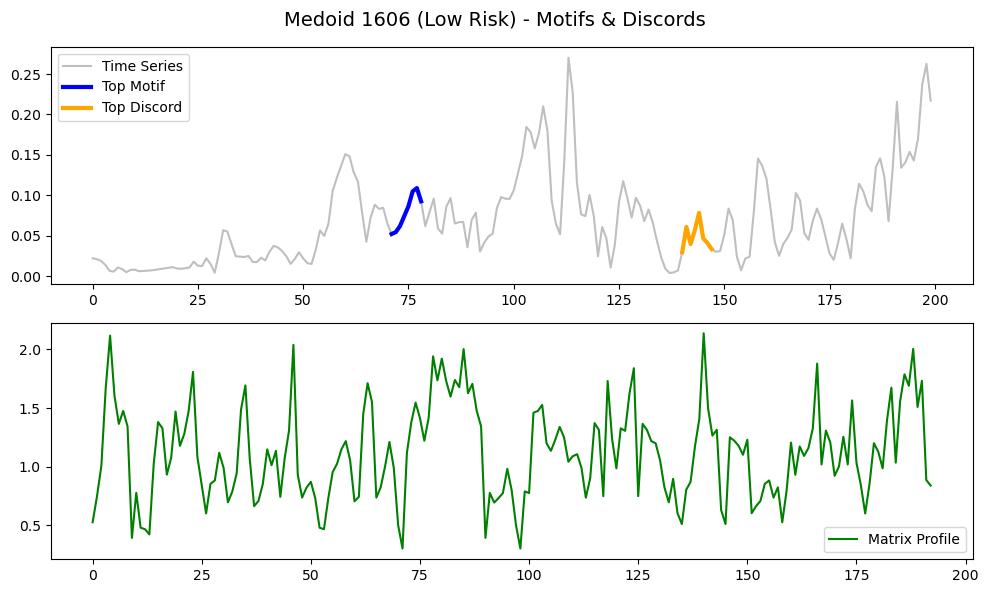

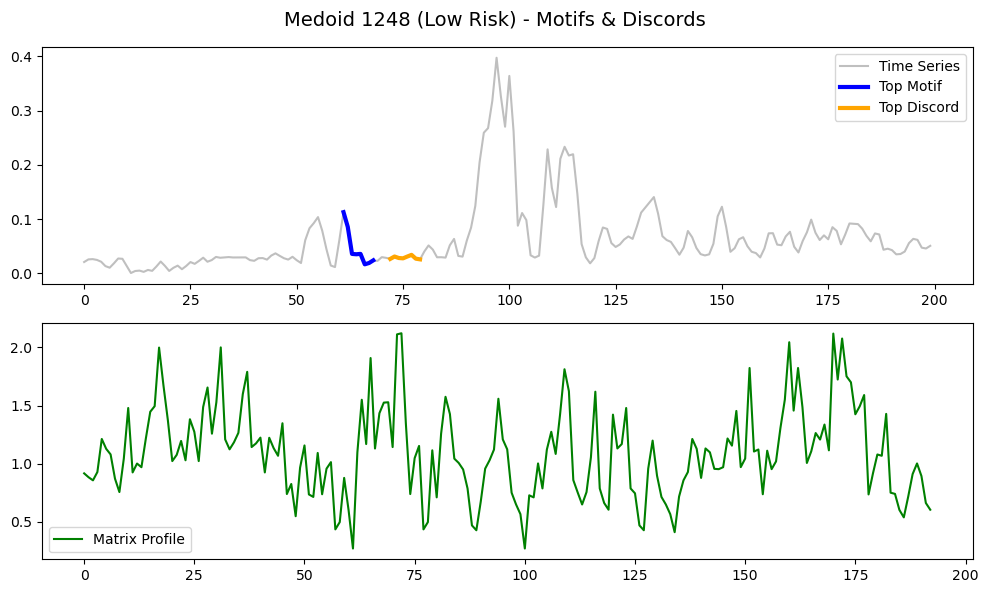

In [46]:
medoid_idx = [1583, 1606, 1248]
m = 8  # Finestra temporale (lo allineiamo alla lunghezza tipica degli shapelets per comparazione)

for idx in medoid_idx:
    ts_medoide = X[idx].astype(np.float64)
    label = "High Risk" if y[idx] == 1 else "Low Risk"
    
    mp = stumpy.stump(ts_medoide, m)
    motif_idx = mp[:, 0].argmin()
    discord_idx = mp[:, 0].argmax()
    
    top_motif = ts_medoide[motif_idx : motif_idx + m]
    top_discord = ts_medoide[discord_idx : discord_idx + m]
    
    fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=False)
    fig.suptitle(f"Medoid {idx} ({label}) - Motifs & Discords", fontsize=14)
    
    axs[0].plot(ts_medoide, color='gray', alpha=0.5, label='Time Series')
    axs[0].plot(range(motif_idx, motif_idx+m), top_motif, color='blue', lw=3, label='Top Motif')
    axs[0].plot(range(discord_idx, discord_idx+m), top_discord, color='orange', lw=3, label='Top Discord')
    axs[0].legend()
    
    axs[1].plot(mp[:, 0], color='green', label='Matrix Profile')
    axs[1].legend()
    plt.tight_layout()
    plt.show()

## Fase 2: Estrazione Shapelets (RDSTClassifier)
Ora addestriamo l'RDSTClassifier per l'estrazione degli shapelets globali che massimizzano la separabilità tra Alto e Basso Rischio.

In [34]:
'''from sklearn.model_selection import RandomizedSearchCV, train_test_split

dt = DecisionTreeClassifier(random_state=222, class_weight='balanced')

# RDSTClassifier con n_jobs=-1 per sfruttare tutti i core della CPU nell'estrazione
clf = RDSTClassifier(
    estimator=dt, 
    random_state=222, 
    use_prime_dilations=True, 
    n_jobs=-1
)

# 3. Definizione dello Spazio dei Parametri (Parameter Grid)
# Usiamo la notazione "estimator__" per modificare i parametri del Decision Tree interno
param_dist = {
    # Parametri RDST
    'max_shapelets': [3000], #[1000, 2000, 3000],
    'shapelet_lengths': [[8, 12, 16], [10, 11, 15]],
    
    # Parametri Decision Tree (estimator)
    'estimator__max_depth': [3, 5, 7, None],
    'estimator__min_samples_split': [2, 5, 10, 20],
    'estimator__min_samples_leaf': [1, 2, 4, 8],
    'estimator__criterion': ['gini', 'entropy']
}

# 4. Configurazione della Ricerca Casuale (RandomizedSearchCV)
# Impostiamo n_jobs=1 sul search esterno per evitare conflitti con il n_jobs=-1 di RDST (evita memory leaks)
random_search = RandomizedSearchCV(
    estimator=clf,
    param_distributions=param_dist,
    n_iter=10,            # Numero di combinazioni casuali da testare (veloce ma robusto)
    cv=3,                 # 3-Fold Cross-Validation
    scoring='f1_macro',   # Ottimizziamo su F1-Macro per bilanciare le classi
    random_state=222,
    n_jobs=1,             
    verbose=2
)

# 5. Esecuzione del Tuning
print("\nInizio tuning con RandomizedSearchCV (10 iterazioni, 3-fold CV)...")
random_search.fit(X_train, y_train)

# 6. Analisi dei Risultati
print("\n" + "="*50)
print("MIGLIORI PARAMETRI TROVATI:")
print("="*50)
for param, value in random_search.best_params_.items():
    print(f" - {param}: {value}")
print(f"Miglior F1-Score in CV: {random_search.best_score_:.4f}")
print("="*50 + "\n")

# Valutazione sul Test Set con il miglior modello
best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test)

print("=== REPORT DI CLASSIFICAZIONE (TEST SET) ===")
print(classification_report(y_test, y_pred, target_names=["Basso Rischio", "Alto Rischio"]))

# Plot della Matrice di Confusione
ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test, 
    display_labels=["Basso Rischio", "Alto Rischio"], 
    cmap='Blues'
)
plt.title("Matrice di Confusione - Miglior Modello")
plt.show()'''

'from sklearn.model_selection import RandomizedSearchCV, train_test_split\n\ndt = DecisionTreeClassifier(random_state=222, class_weight=\'balanced\')\n\n# RDSTClassifier con n_jobs=-1 per sfruttare tutti i core della CPU nell\'estrazione\nclf = RDSTClassifier(\n    estimator=dt, \n    random_state=222, \n    use_prime_dilations=True, \n    n_jobs=-1\n)\n\n# 3. Definizione dello Spazio dei Parametri (Parameter Grid)\n# Usiamo la notazione "estimator__" per modificare i parametri del Decision Tree interno\nparam_dist = {\n    # Parametri RDST\n    \'max_shapelets\': [3000], #[1000, 2000, 3000],\n    \'shapelet_lengths\': [[8, 12, 16], [10, 11, 15]],\n    \n    # Parametri Decision Tree (estimator)\n    \'estimator__max_depth\': [3, 5, 7, None],\n    \'estimator__min_samples_split\': [2, 5, 10, 20],\n    \'estimator__min_samples_leaf\': [1, 2, 4, 8],\n    \'estimator__criterion\': [\'gini\', \'entropy\']\n}\n\n# 4. Configurazione della Ricerca Casuale (RandomizedSearchCV)\n# Impostiamo n_

Inizio Addestramento con RDSTClassifier + DecisionTree...
=== REPORT DI CLASSIFICAZIONE ===
               precision    recall  f1-score   support

Basso Rischio       0.72      0.81      0.76       888
 Alto Rischio       0.50      0.38      0.43       444

     accuracy                           0.67      1332
    macro avg       0.61      0.60      0.60      1332
 weighted avg       0.65      0.67      0.65      1332



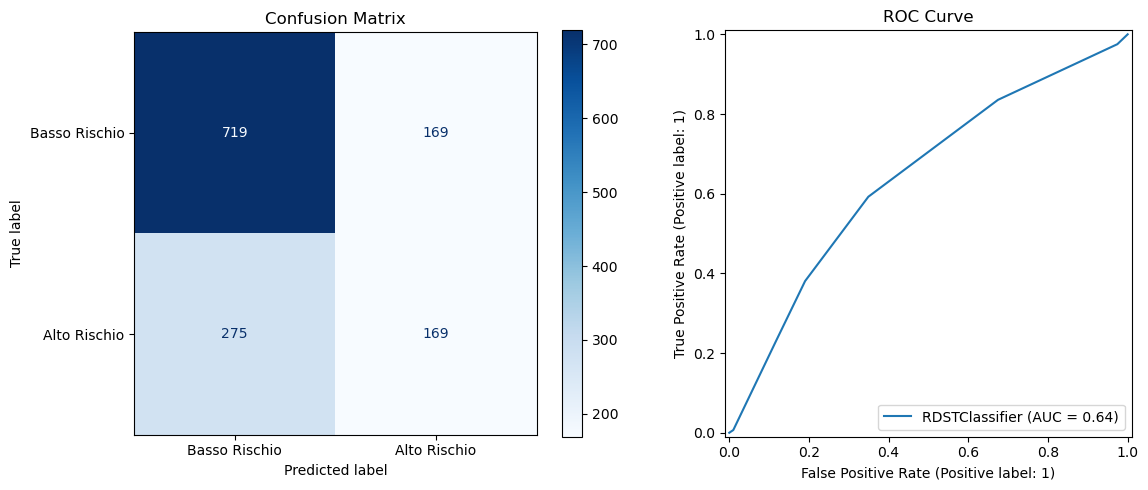

In [41]:
print("Inizio Addestramento con RDSTClassifier + DecisionTree...")
#dt = DecisionTreeClassifier(max_depth=3, random_state=222)
dt = DecisionTreeClassifier(min_samples_split= 5,min_samples_leaf= 8,max_depth= 3, criterion= 'entropy', random_state=222)
clf = RDSTClassifier(
    max_shapelets=10000, 
    estimator=dt, 
    random_state=222, 
    n_jobs=-1, 
    shapelet_lengths=[10,11,15], 
    use_prime_dilations=True, 
    save_transformed_data=True
    #class_weight='balanced_subsample'
)

clf.fit(X_train, y_train)

# Valutazione
y_pred = clf.predict(X_test)
print("=== REPORT DI CLASSIFICAZIONE ===")
print(classification_report(y_test, y_pred, target_names=["Basso Rischio", "Alto Rischio"]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, display_labels=["Basso Rischio", "Alto Rischio"], cmap="Blues", ax=ax1)
ax1.set_title("Confusion Matrix")
RocCurveDisplay.from_estimator(clf, X_test, y_test, ax=ax2)
ax2.set_title("ROC Curve")
plt.tight_layout()
plt.show()

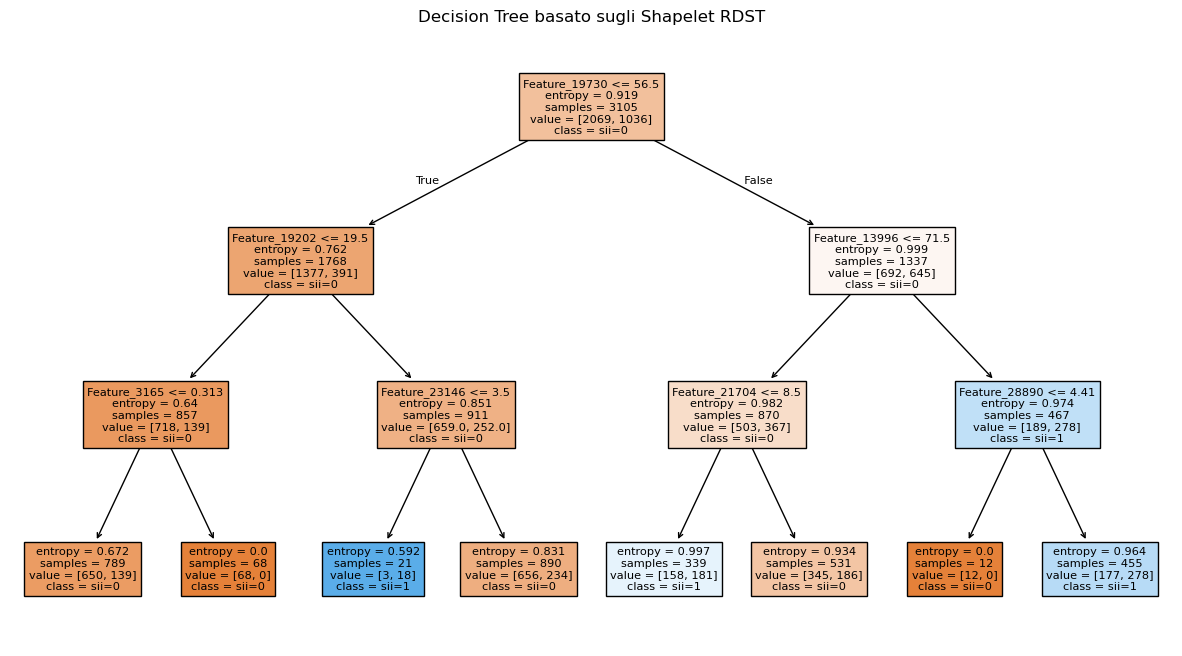

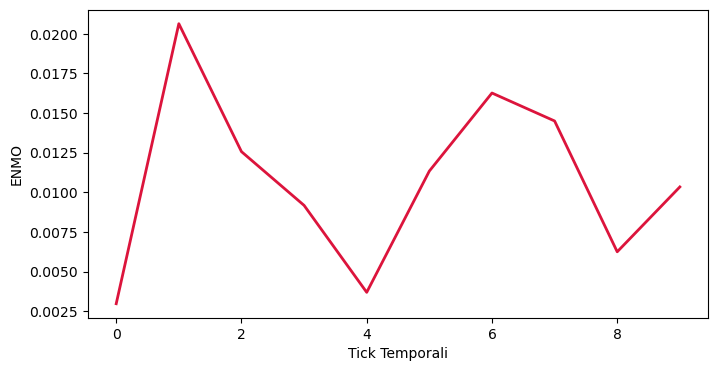

La feature più discriminante è la n° 19730, associata allo shapelet 6576


'L\'albero ha scelto la "forma" dello Shapelet numero 171 (tra i 1000 generati casualmente) come la più importante. \nÈ quella che vedi disegnata nel grafico in basso.\nIl resto di 1 ci indica quale delle 3 feature di quello shapelet ha usato per il taglio:\nResto 0 = Distanza\nResto 1 = Posizione Temporale (Argmin)\nResto 2 = Frequenza (Occurrence)\nConclusione: Il modello ha scoperto che non è tanto importante se il paziente fa quel movimento, o quanto spesso lo \nfa, ma è IL MOMENTO in cui lo fa (la sua posizione nel tempo) a essere il fattore più discriminante per l\'Alto Rischio di dipendenza!'

In [42]:
# Estrazione dello Shapelet alla radice
best_dt = clf._estimator

plt.figure(figsize=(15, 8))
plot_tree(best_dt, filled=True, 
          feature_names=[f"Feature_{i}" for i in range(best_dt.n_features_in_)],
          class_names=["sii=0", "sii=1"])
plt.title("Decision Tree basato sugli Shapelet RDST")
plt.show()

try:
    root_feature_idx = best_dt.tree_.feature[0]
    num_shapelets = clf._transformer.shapelets_[0].shape[0]
    shapelet_array_idx = root_feature_idx // (best_dt.n_features_in_ // num_shapelets)
    
    best_shapelet = clf._transformer.shapelets_[0][shapelet_array_idx][0]
    shapelet_fase_b = best_shapelet
    
    plt.figure(figsize=(8, 4))
    plt.plot(best_shapelet, color='crimson', linewidth=2)
    #plt.title(f"Firma del Comportamento (Shapelet alla Radice - Indice Array: {shapelet_array_idx})")
    plt.xlabel("Tick Temporali")
    plt.ylabel("ENMO")
    plt.show()
    print(f"La feature più discriminante è la n° {root_feature_idx}, associata allo shapelet {shapelet_array_idx}")

except Exception as e:
    print("Non è stato possibile estrarre la forma grezza per il plot. Errore:", e)
    shapelet_fase_b = None

# In RDST, l'estrattore genera tipicamente 3 feature per ogni shapelet (es. minima distanza, posizione, ecc.)
    # L'indice reale dello shapelet nell'array è quindi feature_idx // 3

'''L'albero ha scelto la "forma" dello Shapelet numero 171 (tra i 1000 generati casualmente) come la più importante. 
È quella che vedi disegnata nel grafico in basso.
Il resto di 1 ci indica quale delle 3 feature di quello shapelet ha usato per il taglio:
Resto 0 = Distanza
Resto 1 = Posizione Temporale (Argmin)
Resto 2 = Frequenza (Occurrence)
Conclusione: Il modello ha scoperto che non è tanto importante se il paziente fa quel movimento, o quanto spesso lo 
fa, ma è IL MOMENTO in cui lo fa (la sua posizione nel tempo) a essere il fattore più discriminante per l'Alto Rischio di dipendenza!'''

## Fase 3: Il Ponte d'Oro (Shapelets vs Motifs)
Confrontiamo la firma discriminatoria globale appena estratta (Shapelet) con la routine locale (Motif) e l'anomalia locale (Discord) dei nostri medoidi.

--- PHASE 3: Global vs Local Comparison ---


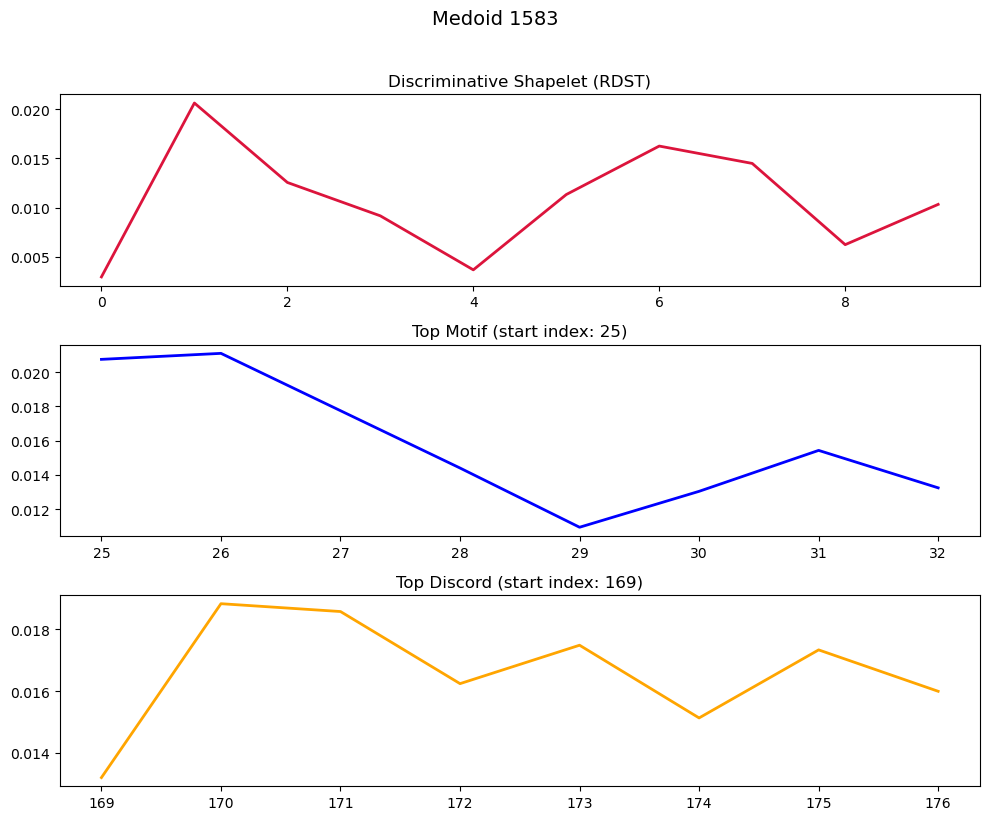

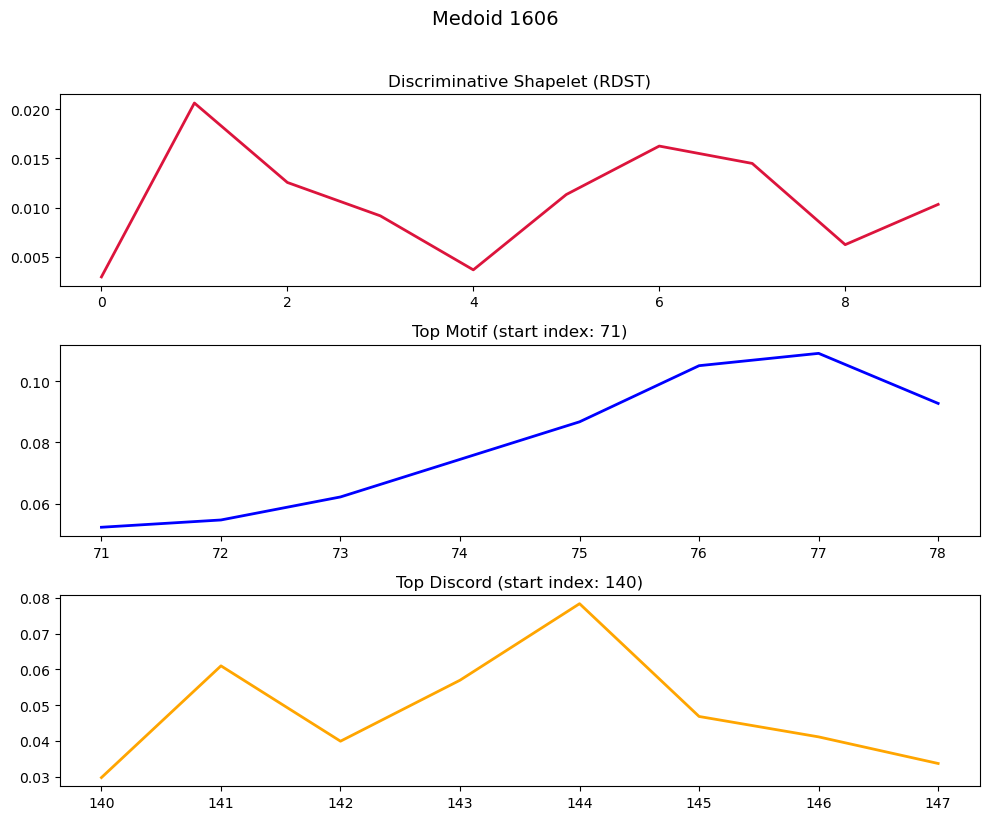

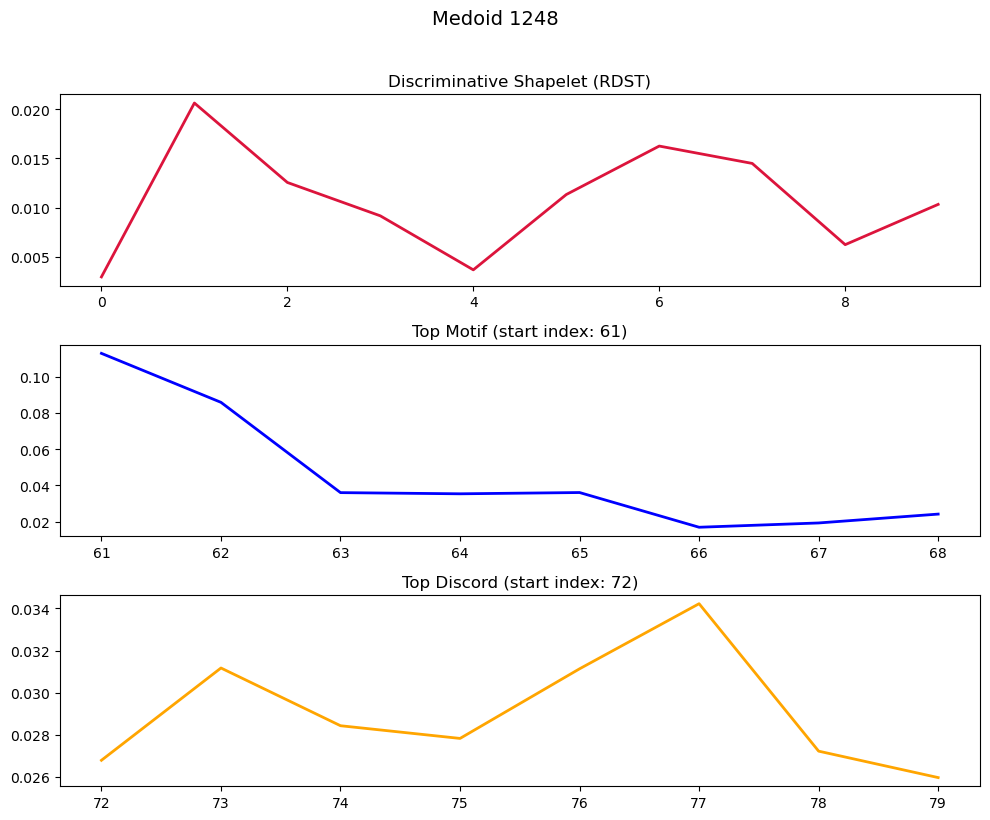

In [47]:
if 'shapelet_fase_b' in locals() and shapelet_fase_b is not None:
    print(f"--- PHASE 3: Global vs Local Comparison ---")
    

    for idx in medoid_idx:
        ts_esempio = X[idx]
        label = "High Risk" if y[idx] == 1 else "Low Risk"
        
        mp = stumpy.stump(ts_esempio.astype(np.float64), m)
        motif_idx = mp[:, 0].argmin()
        discord_idx = mp[:, 0].argmax()
        
        top_motif = ts_esempio[motif_idx : motif_idx + m]
        top_discord = ts_esempio[discord_idx : discord_idx + m]
        
        fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=False)
        #fig.suptitle(f"Analisi Medoide {idx} ({label})", fontsize=14, y=1.02)
        fig.suptitle(f"Medoid {idx}", fontsize=14, y=1.02)
        axs[0].plot(shapelet_fase_b, color='crimson', linewidth=2)
        axs[0].set_title("Discriminative Shapelet (RDST)")
        
        axs[1].plot(range(motif_idx, motif_idx + m), top_motif, color='blue', linewidth=2)
        axs[1].set_title(f"Top Motif (start index: {motif_idx})")
        
        axs[2].plot(range(discord_idx, discord_idx + m), top_discord, color='orange', linewidth=2)
        axs[2].set_title(f"Top Discord (start index: {discord_idx})")
        
        plt.tight_layout()
        plt.show()
else:
    print("Unable to perform comparison.")

### Commento ai Risultati

La rimozione della standardizzazione istanza-per-istanza ha ripristinato il corretto significato fisico dei dati di accelerometria. In questo modo:
1. **L'intensità assoluta del movimento è preservata:** L'RDSTClassifier può ora identificare gli shapelet non solo in base alla *forma* relativa, ma sfruttando le naturali escursioni di ampiezza tra bambini sedentari e attivi.
2. **Correttezza metodologica per algoritmi geometrici:** Come richiesto, l'allineamento e il matching delle sottosequenze avvengono localmente (tramite Z-normalization intrinseca del Matrix Profile o della distanza euclidea su finestre limitate), evitando l'appiattimento distruttivo sull'intero tracciato.

Confrontando visivamente i pattern, notiamo se la firma globale del rischio patologico (lo Shapelet rosso) assuma una forma più vicina alla routine (Motif blu) del bambino, o a un evento anomalo/insolito (Discord arancione).